<a href="https://colab.research.google.com/github/maramgueye/datascience_with_python/blob/main/Final_Assessment_Gueye_Maram_studentID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Firstly, let's make the relavant import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Python exercise: Perfect numbers
Definition: A perfect number is a positive integer that is equal to the sum of its proper divisors (excluding the
number itself). For example:

• 6 is a perfect number because its divisors (excluding 6) are 1, 2, and 3, and 1 + 2 + 3 = 6.

• 28 is a perfect number because its divisors (excluding 28) are 1, 2, 4, 7, and 14, and 1 + 2 + 4 + 7 + 14 = 28.

1. Write a Python function is_perfect_number(n) that checks whether a given integer n is a perfect number.
The function should return True if n is a perfect number and False otherwise.
Example:
1 print(is_perfect_number(6)) # Output: True
2 print(is_perfect_number(28)) # Output: True
3 print(is_perfect_number(12)) # Output: False
Describe and summarize the dataset
Dataset 1: Customer invoices
The data_invoices.xlsx dataset contains information about customer invoices. It has the following
columns:
• id_invoice: unique identifier for each invoice.
• amount: monetary value of each invoice
• age customer: age of the customer associated with each invoice.
• items bought: number of items purchased in each invoice.
• debit card: binary indicator representing whether a debit card was used for the purchase.
– 1 indicates a debit card was used.
– 0 indicates a debit card was not used.

In [2]:
def is_perfect_number(n):
    '''Test if n is a perfect number'''
    #we will firstly take the divisor of the number n excluding n itselves
    div=[]
    for i in range (1, n):
        if n%i==0:
            div.append(i)
    #then we are going to do the sum of the divisor and verify if the result is equal to our number n
    div=np.array(div)
    if div.sum()==n:
        return True
    else:
        return False

Let's run tests with the example given and other non perfect number

In [3]:
#test
test_lst=[6, 7, 12,28]
for n in test_lst:
    if is_perfect_number(n):
        print (f'{n} is a perfect number')
    else :
        print(f'{n} is not a perfect number')

6 is a perfect number
7 is not a perfect number
12 is not a perfect number
28 is a perfect number


# Describe and summarize the dataset

### 1. Load the data_invoices.xlsx dataset and compute the following descriptive statistics for all continuous variables:
   
(a) Mean

(b) Median

(c) Variance

(d) Standard deviation

(e) Minimum and maximum values

(f) First and third quartiles

La cellule suivant est a execute uniquement si le fichier est lu sur google collab, sinon passe au cellule suivant

In [4]:
from google.colab import files

uploaded = files.upload()

Saving data_invoices (2).xlsx to data_invoices (2).xlsx


In [7]:
data=pd.read_excel('data_invoices (2).xlsx', sheet_name='data_invoices')

data.head(7)

,id_invoice,amount,age customer,items bought,debit card
0,1,163.5,43,7,0
1,2,138.8,39,5,0
2,3,175.9,48,7,1
3,4,157.5,45,11,1
4,5,600.0,43,2,0
5,6,132.8,32,5,0
6,7,165.7,42,3,1


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_invoice    2000 non-null   int64  
 1   amount        2000 non-null   float64
 2   age customer  2000 non-null   int64  
 3   items bought  2000 non-null   int64  
 4   debit card    2000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 78.3 KB


In [9]:
data.isnull().sum()

,0
id_invoice,0
amount,0
age customer,0
items bought,0
debit card,0


In [10]:
data.shape

(2000, 5)

We can see that their is no missing values in our dataset

In [11]:
data.describe(include='all')


,id_invoice,amount,age customer,items bought,debit card
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1000.500000,154.153150,40.072000,8.513500,0.702500
std,577.494589,30.487148,5.052483,4.743635,0.457273
min,1.000000,20.000000,24.000000,0.000000,0.000000
25%,500.750000,134.975000,37.000000,5.000000,0.000000
50%,1000.500000,154.750000,40.000000,8.000000,1.000000
75%,1500.250000,172.525000,43.000000,12.000000,1.000000
max,2000.000000,600.000000,58.000000,32.000000,1.000000


In [12]:
print(f'      The variances are: \n{data.var()}')

      The variances are: 
id_invoice      333500.000000
amount             929.466183
age customer        25.527580
items bought        22.502069
debit card           0.209098
dtype: float64


### 2. For the categorical variables, count the occurrences of each unique value.
It is only the column debit card that hav categorical variables with 0 representing 'No' and 1 representing 'Yes'

In [13]:
counts = data['debit card'].value_counts()
counts

,count
debit card,
1,1405
0,595


In [14]:
# let's take the percentage of the occurence each of the categorical variables
counts = data['debit card'].value_counts(normalize=True)*100
counts

,proportion
debit card,
1,70.25
0,29.75


We can see that there is a majority of payment by debit card with a percentage of 70.25% and only 29.75% that did not pay by card

### 3. Choose the most appropriate visuals to display the distribution of each continuous variable. Justify your choice.

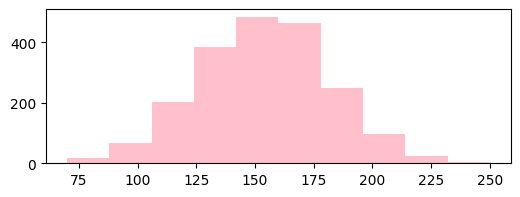

In [15]:
plt.figure(figsize=(6,2))
plt.hist(data['amount'], range=(70, 250),color='pink')
plt.show()

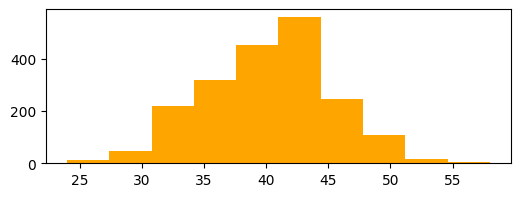

In [16]:
plt.figure(figsize=(6,2))
plt.hist(data['age customer'], color='orange')
plt.show()

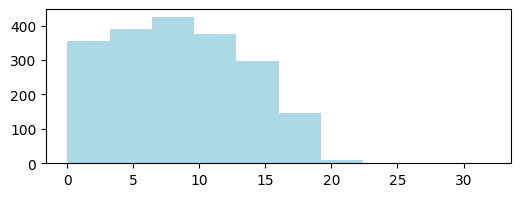

In [17]:
plt.figure(figsize=(6,2))
plt.hist(data['items bought'], color='lightblue')
plt.show()

### We have 3 plots, we can put them in the same subplot to see all three of them at the same tiem

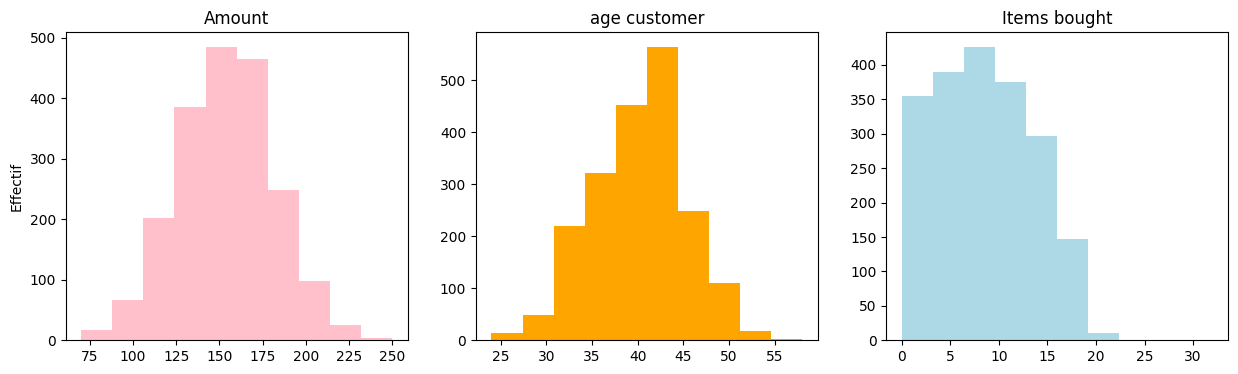

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# amount
ax[0].hist(data['amount'], range=(70, 250), color='pink')
ax[0].set_title('Amount')
ax[0].set_ylabel('Effectif')
# age customer
ax[1].hist(data['age customer'], color='orange')
ax[1].set_title('age customer')
# items bought
ax[2].hist(data['items bought'], color='lightblue')
ax[2].set_title('Items bought')

#plt.tight_layout()
plt.show()

### 4. Choose the most appropriate visuals to display the frequency of each value for categorical variables. Justify your choice.

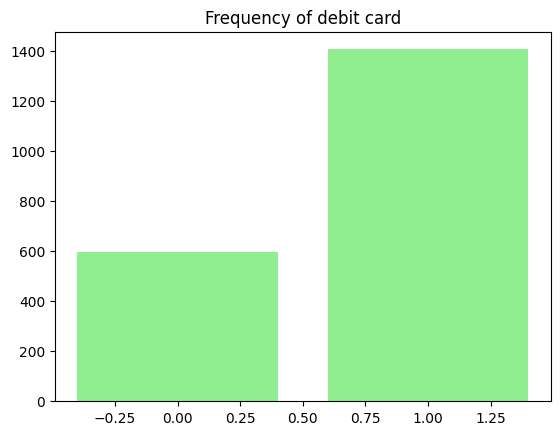

In [19]:
counts = data['debit card'].value_counts()
plt.bar(counts.index, counts.values, color='lightgreen')
plt.title('Frequency of debit card')
plt.show()

In [ ]:
plt.bar??

Signature:
plt.bar(
    x: 'float | ArrayLike',
    height: 'float | ArrayLike',
    width: 'float | ArrayLike' = 0.8,
    bottom: 'float | ArrayLike | None' = None,
    *,
    align: "Literal['center', 'edge']" = 'center',
    data: 'DataParamType' = None,
    **kwargs,
) -> 'BarContainer'
Docstring:
Make a bar plot.

The bars are positioned at *x* with the given *align*\ment. Their
dimensions are given by *height* and *width*. The vertical baseline
is *bottom* (default 0).

Many parameters can take either a single value applying to all bars
or a sequence of values, one for each bar.

Parameters
----------
x : float or array-like
    The x coordinates of the bars. See also *align* for the
    alignment of the bars to the coordinates.

    Bars are often used for categorical data, i.e. string labels below
    the bars. You can provide a list of strings directly to *x*.
    ``bar(['A', 'B', 'C'], [1, 2, 3])`` is often a shorter and more
    convenient notation compared to
    ``bar(rang

### 5. Compute the correlation between the column amount and age customer, as well as between amount and items bought.

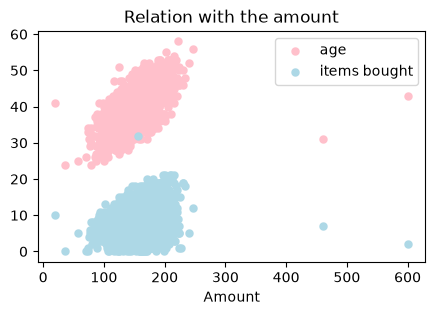

In [ ]:
plt.figure(figsize=(5,3))
plt.scatter(data['amount'], data['age customer'], color='pink', label= 'age', linewidths=0.05)
plt.scatter(data['amount'], data['items bought'], color='lightblue', label= 'items bought', linewidths=0.05)
plt.legend()
plt.xlabel('Amount')
plt.title("Relation with the amount")
plt.show()

In [ ]:
data[['amount', 'age customer']].corr()

,amount,age customer
amount,1.000000,0.615239
age customer,0.615239,1.000000


In [ ]:
data[['amount', 'items bought']].corr()

,amount,items bought
amount,1.000000,0.234581
items bought,0.234581,1.000000


### 6. Interpret the correlation results.

### 7. Choose the most appropriate visualization to summarize the distribution of the amounts paid by clients who used a debit card and those who did not. Justify your choice

# Linear Regression
1. Build a linear regression model where the dependent variable is amount, and the independent variables are
age customer, items bought and credit card.

- (a) Report the coefficients and intercept of the model.



In [22]:
data.head(10)

,id_invoice,amount,age customer,items bought,debit card
0,1,163.5,43,7,0
1,2,138.8,39,5,0
2,3,175.9,48,7,1
3,4,157.5,45,11,1
4,5,600.0,43,2,0
5,6,132.8,32,5,0
6,7,165.7,42,3,1
7,8,134.1,39,2,1
8,9,174.0,39,1,1
9,10,183.7,41,11,1


In [25]:
from sklearn.linear_model import LinearRegression
Y = data[['age customer', 'items bought', 'debit card']].values
X = data[['amount']].values
multi_model = LinearRegression().fit(X, Y)
coefficients=multi_model.coef_
intercept = multi_model.intercept_
print(coefficients, intercept)

[[0.10196047]
 [0.03649947]
 [0.00250701]] [24.35447259  2.88699224  0.31603714]


0.15382829492485364


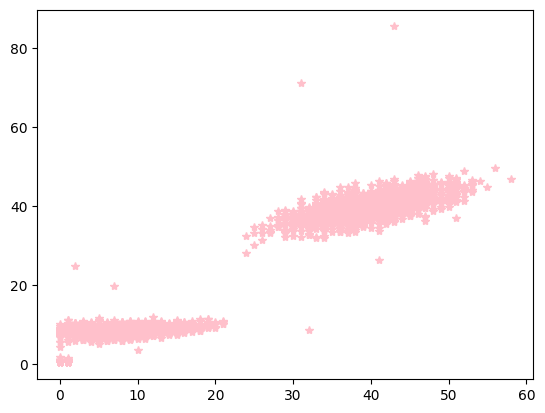

In [27]:
Y_pred =multi_model.predict(X)
plt.plot(Y, Y_pred, '*', color='pink')
print(multi_model.score(X, Y))

- (b) Interpret the meaning of each coefficient.



- (c) Compute and report the R-squared statistic and explain what it tells you about the model’s fit

In [29]:
X_expanded = np.concatenate([X, X**2, X**3], axis=1)
print('R2:',multi_model.score(X_expanded, Y))

ValueError: X has 3 features, but LinearRegression is expecting 1 features as input.